# 05 – When should we contact them?

When do users order (day and hour), and does the weekend make a difference?
Data: dbt table `otto.mart_sessions`.

In [1]:
import os
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine
from statsmodels.stats.proportion import proportions_ztest

sns.set_theme(style="white", font_scale=1.1)

DATA_DIR = Path("../data/processed")
FIG_DIR = Path("../docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

## Load the data

Same file as notebook 04 (downloaded once from PostgreSQL).

In [2]:
DATA_FILE = DATA_DIR / "mart_sessions_all.parquet"

if DATA_FILE.exists():
    sessions = pd.read_parquet(DATA_FILE)
else:
    load_dotenv("../.env", override=True)
    engine = create_engine(
        f"postgresql://{os.getenv('POSTGRES_USER')}:{os.getenv('POSTGRES_PASS')}"
        f"@{os.getenv('POSTGRES_HOST')}:{os.getenv('POSTGRES_PORT')}/{os.getenv('POSTGRES_DB')}"
    )
    sessions = pd.read_sql("SELECT * FROM otto.mart_sessions", engine)
    sessions.to_parquet(DATA_FILE, index=False)

print(sessions.shape)

(1000000, 20)


## 1. When do users order?

Time of the first order of every buyer. August 1–28 has every weekday exactly 4 times, so the days can be compared directly.

In [3]:
orders = sessions[sessions["has_order"]].copy()
orders["order_hour"] = orders["order_hour"].astype(int)

heat = orders.pivot_table(index="order_weekday", columns="order_hour", values="session_id", aggfunc="count")
heat = heat.reindex(DAYS)

# busiest day and hour
peak_day, peak_hour = heat.stack().idxmax()
print(f"Most orders: {peak_day} at {peak_hour}:00")
print()
print(orders["order_weekday"].value_counts().reindex(DAYS))

Most orders: Monday at 21:00

order_weekday
Monday       20376
Tuesday      19552
Wednesday    18333
Thursday     16621
Friday       15843
Saturday     15359
Sunday       20082
Name: count, dtype: int64


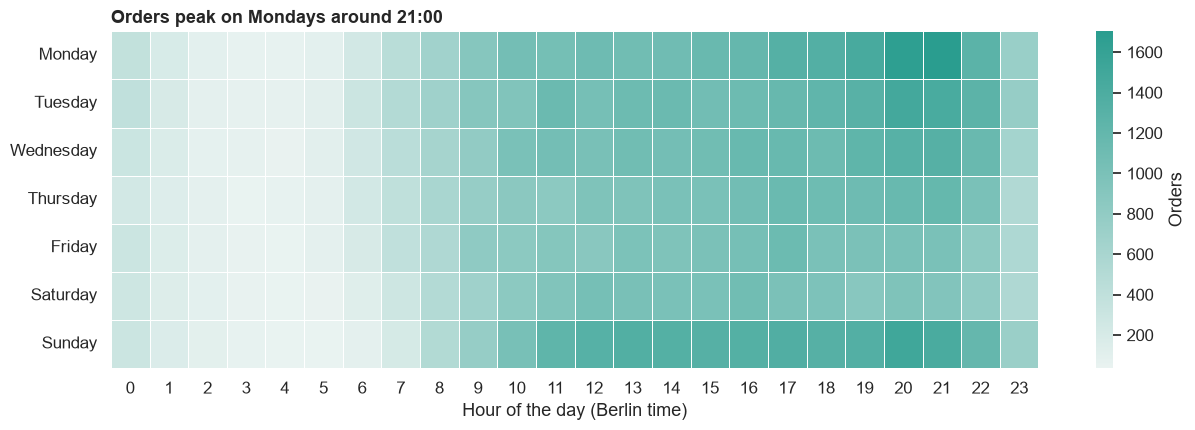

In [4]:
fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(heat, cmap=sns.light_palette("#2a9d8f", as_cmap=True), linewidths=0.5, cbar_kws={"label": "Orders"}, ax=ax)

ax.set_title(f"Orders peak on {peak_day}s around {peak_hour}:00", loc="left", fontweight="bold")
ax.set_xlabel("Hour of the day (Berlin time)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_orders_by_day_and_hour.png", dpi=200)
plt.show()

## 2. Do weekend users buy more?

Order rate of users who started on a weekend vs. a weekday, tested with a two-proportion z-test.

In [5]:
sessions["start_weekend"] = sessions["start_weekday"].isin(["Saturday", "Sunday"])

weekend_test = sessions.groupby("start_weekend")["has_order"].agg(["sum", "count"])
weekend_test.columns = ["buyers", "users"]
weekend_test["order_rate_%"] = weekend_test["buyers"] / weekend_test["users"] * 100
weekend_test.index = ["Weekday", "Weekend"]
weekend_test

,buyers,users,order_rate_%
Weekday,98552,743642,13.252613
Weekend,27614,256358,10.771655


In [6]:
z_stat, p_value = proportions_ztest(weekend_test["buyers"], weekend_test["users"])
difference = weekend_test.loc["Weekend", "order_rate_%"] - weekend_test.loc["Weekday", "order_rate_%"]

print(f"Difference: {difference:+.2f} percentage points")
print(f"p-value:    {p_value:.4f}")
if p_value < 0.05:
    print("The difference is statistically significant (not just chance).")
else:
    print("No significant difference.")

Difference: -2.48 percentage points
p-value:    0.0000
The difference is statistically significant (not just chance).


With 1M users even a small difference can be significant, so the size of the difference matters as much as the p-value.